# 3. Apprentissage d'un CNN sur le dataset MNIST
*Objectif: Apprendre à classifier les images de chiffres manuscripts (0 à 9) à l'aide d'un réseau de neurones convolutif (CNN)*

In [1]:
#importing libraries from libs.py

from libs import *        # np, pd, plt, tf, keras, layers, train_test_split, ...


In [2]:
from tensorflow.keras import datasets
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

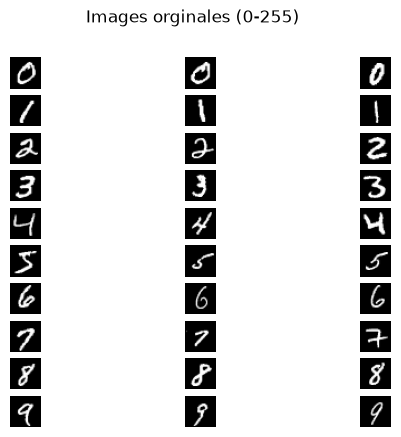

In [3]:
import matplotlib.pyplot as plt
for digit in range(10):
    idx = [j for j, label in enumerate(y_train) if label == digit][:3]
    for i, j in enumerate(idx):
        plt.subplot(10,3, digit*3 +i + 1)
        plt.imshow(X_train_raw[j], cmap='gray')
        
        plt.axis('off')
plt.suptitle("Images orginales (0-255)")
plt.show()

Normalisation: les pixels passent de 0-255 à 0-1

In [4]:
X_train = X_train_raw.astype("float32")/255.0
X_test = X_test_raw.astype("float32") /255.0

Ajout du canal: (N,28,,28) devient(N,28,28,1)

In [5]:
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print("Formes finales : ", X_train.shape, X_test.shape)

Formes finales :  (60000, 28, 28, 1) (10000, 28, 28, 1)


In [6]:

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])


In [7]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [8]:
#model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

```La Validatio est prélevée dans le train (validation_split): le jeu de test reste inconnu jusqu'à l'évaluation finale```

In [9]:
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.9184 - loss: 0.2660 - val_accuracy: 0.9825 - val_loss: 0.0590
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9770 - loss: 0.0788 - val_accuracy: 0.9893 - val_loss: 0.0372
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9827 - loss: 0.0561 - val_accuracy: 0.9893 - val_loss: 0.0364
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9863 - loss: 0.0465 - val_accuracy: 0.9908 - val_loss: 0.0334
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9878 - loss: 0.0387 - val_accuracy: 0.9922 - val_loss: 0.0283


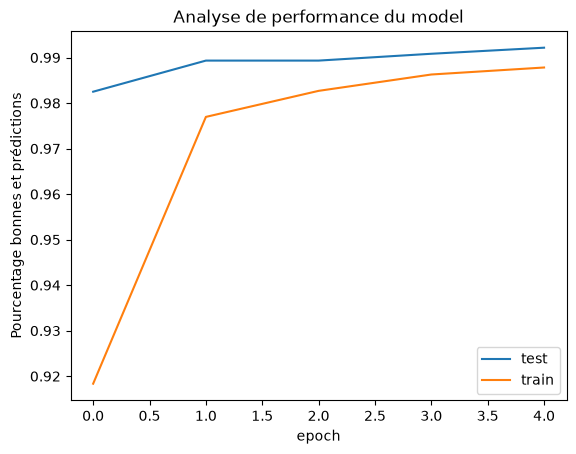

In [10]:
# plot

plt.plot(history.history["val_accuracy"])
plt.plot(history.history["accuracy"])
plt.title("Analyse de performance du model")
plt.xlabel("epoch")
plt.ylabel("Pourcentage bonnes et prédictions")
plt.legend(["test", "train"])

In [11]:
loss, acc=model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {acc*100:.2f}")

313/313 - 1s - 3ms/step - accuracy: 0.9919 - loss: 0.0252

Précision sur le test: 99.19


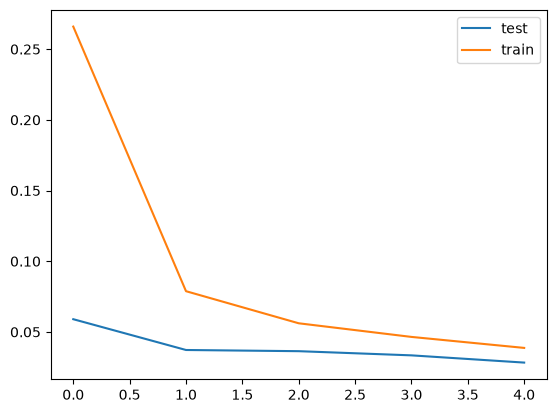

In [12]:
# # La fonction d'erreur est croissante sur les epoch
plt.plot(history.history["val_loss"])
plt.plot(history.history["loss"])
plt.legend(["test", "train"])

In [13]:
y_pred = np.argmax(model.predict(X_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


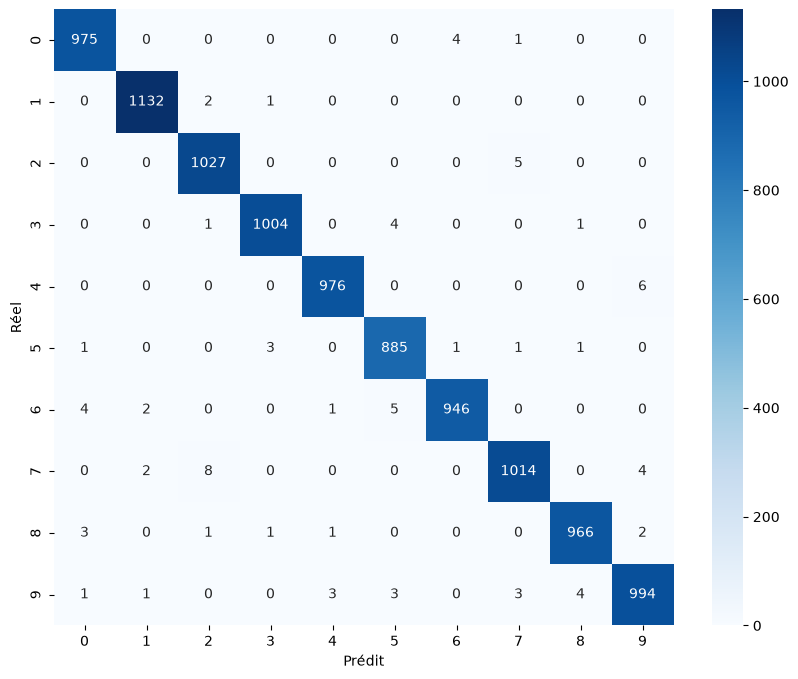

In [14]:
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

In [15]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       1.00      1.00      1.00      1135
           2       0.99      1.00      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



#### Terminologies

- **Conv2D:** slides small filters (for example 3×3) over an image to detect local patterns such as edges, textures and shapes. It outputs feature maps, and the filter weights are learned during training.
- **MaxPooling2D:** shrinks each feature map by keeping only the maximum value in each small window (usually 2×2). This reduces the size and computation and makes the network less sensitive to the exact position of a feature.
- **Flatten:** reshapes the 2D feature maps into a single 1D vector, so they can be fed into Dense layers. It has no weights to learn.
- **Dense:** a fully connected layer in which every input neuron connects to every output neuron. It combines the extracted features to make the decision, and the last Dense layer gives the class probabilities (softmax).
- **Dropout:** during training, it randomly switches off a fraction of the neurons (for example 0.5 means 50%). This stops the network from relying too much on specific neurons, which reduces overfitting. It is inactive at prediction time.

A typical CNN chains them in this order: `Conv2D → MaxPooling2D` (repeated) `→ Flatten → Dense → Dropout → Dense`.